# Airline passengers Forecasting with Prophet

This project analyzes monthly  from **Jan 1, 1949, to Dec 1, 1960**, using Python and Prophet. The aim is to understand identify changes in the underlying trend, and forecast future number of passengers.

The analysis includes:

- Data preparation and exploratory analysis.
- Monthly seasonality and trend changepoint detection.
- A 24 months forecast with uncertainty intervals.
- Forecast evaluation using RMSE.


**Tools:** Python, pandas, Prophet, Matplotlib, and Jupyter Notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
import prophet

In [2]:
df = pd.read_csv('airline_passengers.csv')
df

,Month,Thousands of Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121
...,...,...
139,1960-08,606
140,1960-09,508
141,1960-10,461
142,1960-11,390


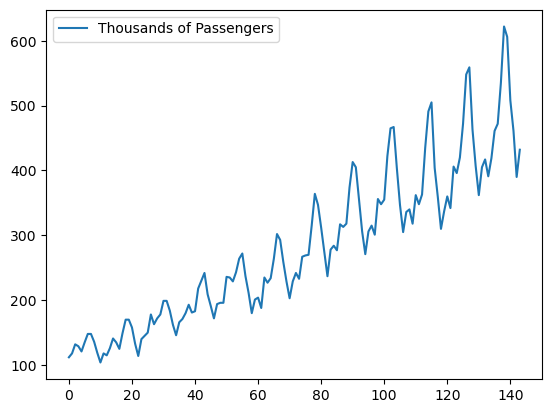

In [4]:
# We plot the data to see how value changes over time
df.plot();

```
As the graph illustrates, we have a seasonality(multiplicative)
```

In [ ]:
# We do the following process step by step for data prepration

# 1_ we check the length of data
# make sure to define the columns name 'ds' and 'y', so the Prophet model recognize them.
# 2_ then we split it into train-test datasets
# 3_ we fit the Prophet model into train dataset
# 4_ we make a 24 months future dataframe with monthly freq.
# 5_ we predict the values 
# 6_ we plot the predicted values and then plot the test dataset to evaluate our model.
# 7_ we use RMSE to see the difference between our true dataset and predicted oone.

In [6]:
len(df)

144

In [7]:
df.columns = ['ds','y']

In [8]:
train = df.iloc[:120]
test = df.iloc[120:]

In [9]:
from prophet import Prophet

model = Prophet(seasonality_mode='multiplicative')
model.fit(train)

00:19:47 - cmdstanpy - INFO - Chain [1] start processing
00:19:47 - cmdstanpy - INFO - Chain [1] done processing


In [10]:
forecastd_date = model.make_future_dataframe(periods=24, freq='MS')

In [11]:
forecast = model.predict(forecastd_date)

In [14]:
print(len(forecast))

144


```
As you see, the forecastd values includes the whole dataset.
````

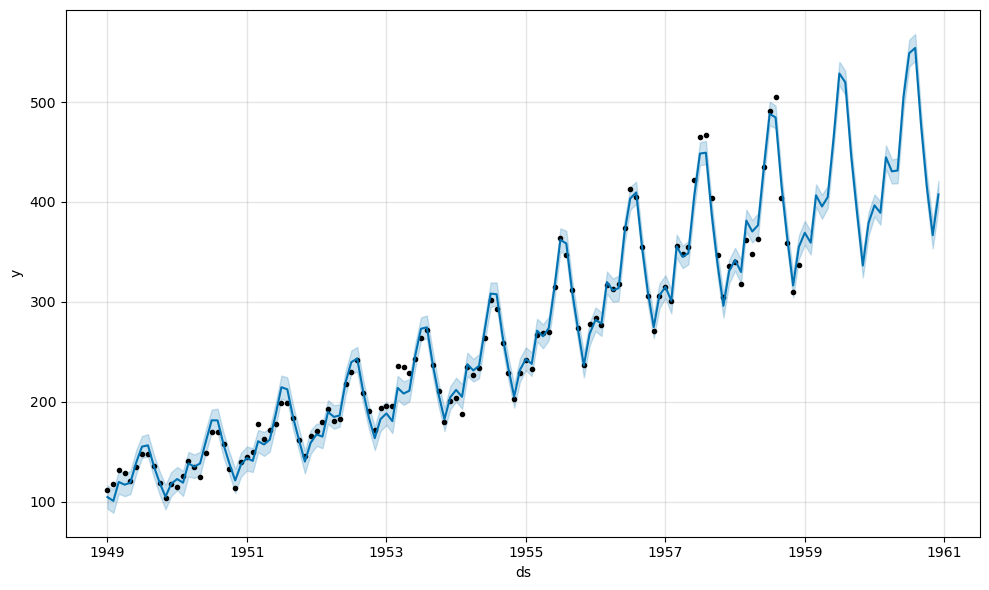

In [15]:
model.plot(forecast);

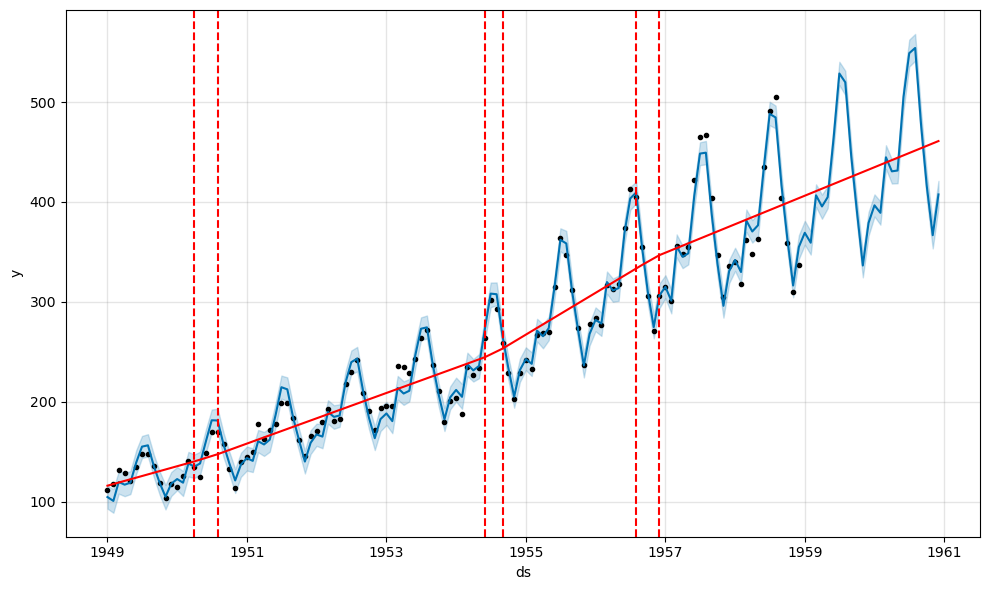

In [35]:
from prophet.plot import add_changepoints_to_plot

# to see the trend changes over time we can apply add_cahngepoints to plot

fig = model.plot(forecast)
a = add_changepoints_to_plot(fig.gca(),model,forecast)

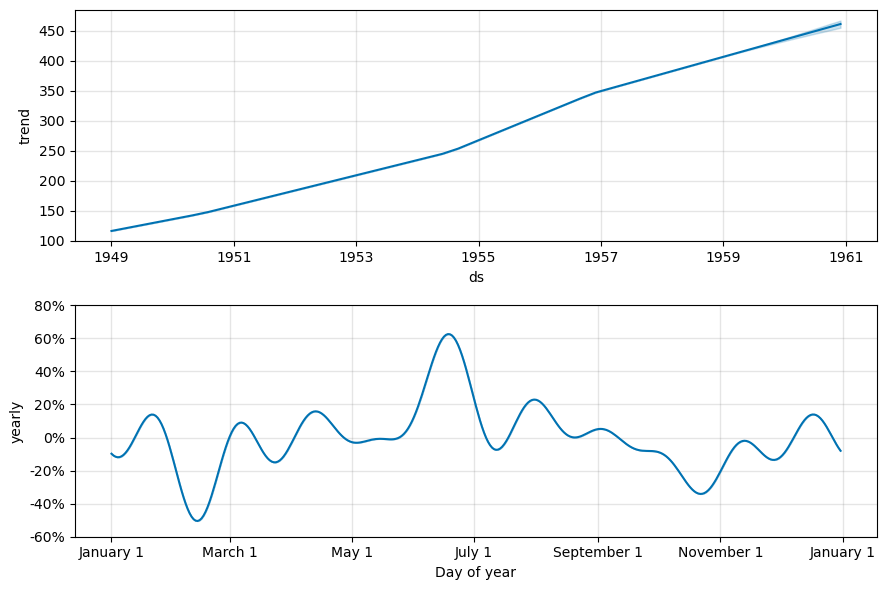

In [33]:
fig = model.plot_components(forecast);

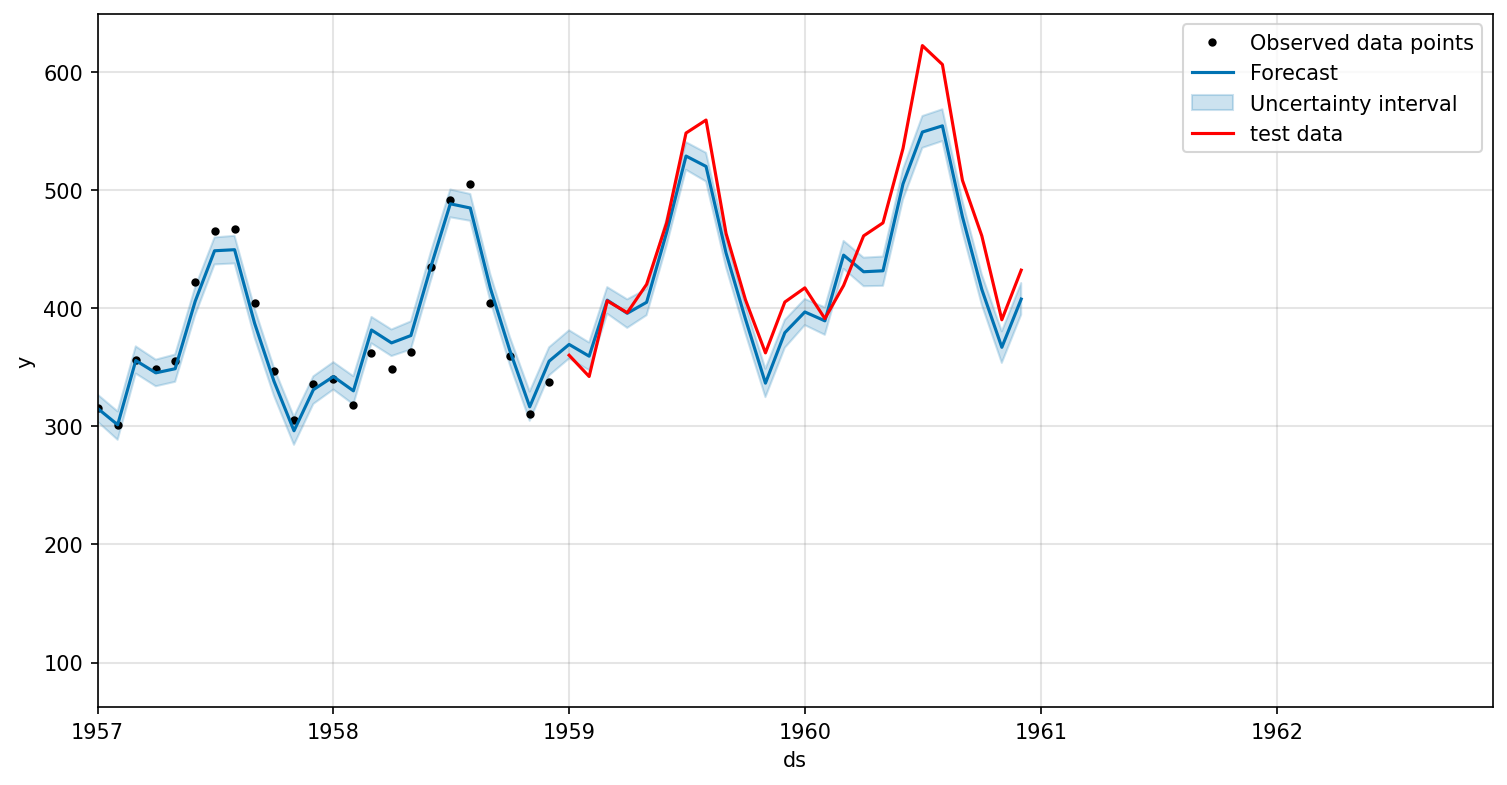

In [24]:
fig, ax = plt.subplots(figsize=(12,6), dpi=150)

model.plot(forecast, ax=ax)

ax.plot(
    pd.to_datetime(test['ds']),
    test['y'],
    color='r',
    label='test data'
)

ax.set_xlim(
    pd.to_datetime('1957-01-01'),
    pd.to_datetime('1962-12-01')
)
plt.legend();

```
The prophet model has done a fantastic job here.
````

In [25]:
# Let's see how we are far from the real values

preds = forecast.iloc[-24:]['yhat']
real_values = test['y']

In [26]:
len(preds)

24

In [29]:
len(preds)

24

In [27]:
from statsmodels.tools.eval_measures import rmse

In [28]:
print(rmse(real_values,preds))

29.720895370922122


In [31]:
real_values.mean()

452.25

```
We have done pretty well prediction.
```